In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/uciml/red-wine-quality-cortez-et-al-2009/winequality-red.csv


In [3]:
df = pd.read_csv('/kaggle/input/datasets/uciml/red-wine-quality-cortez-et-al-2009/winequality-red.csv')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Shape: (1599, 12)

Columns:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64

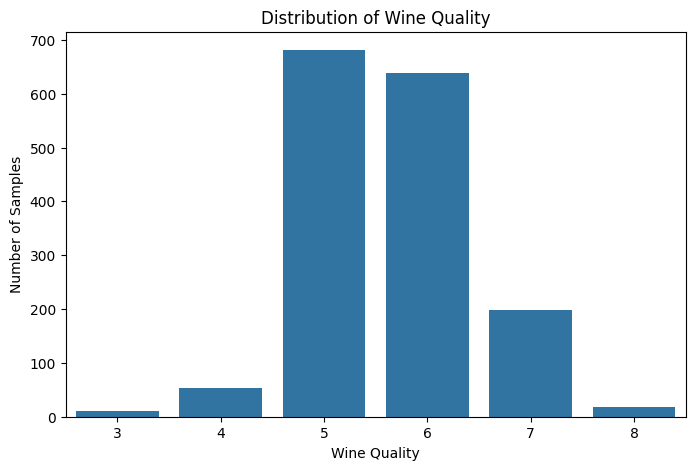

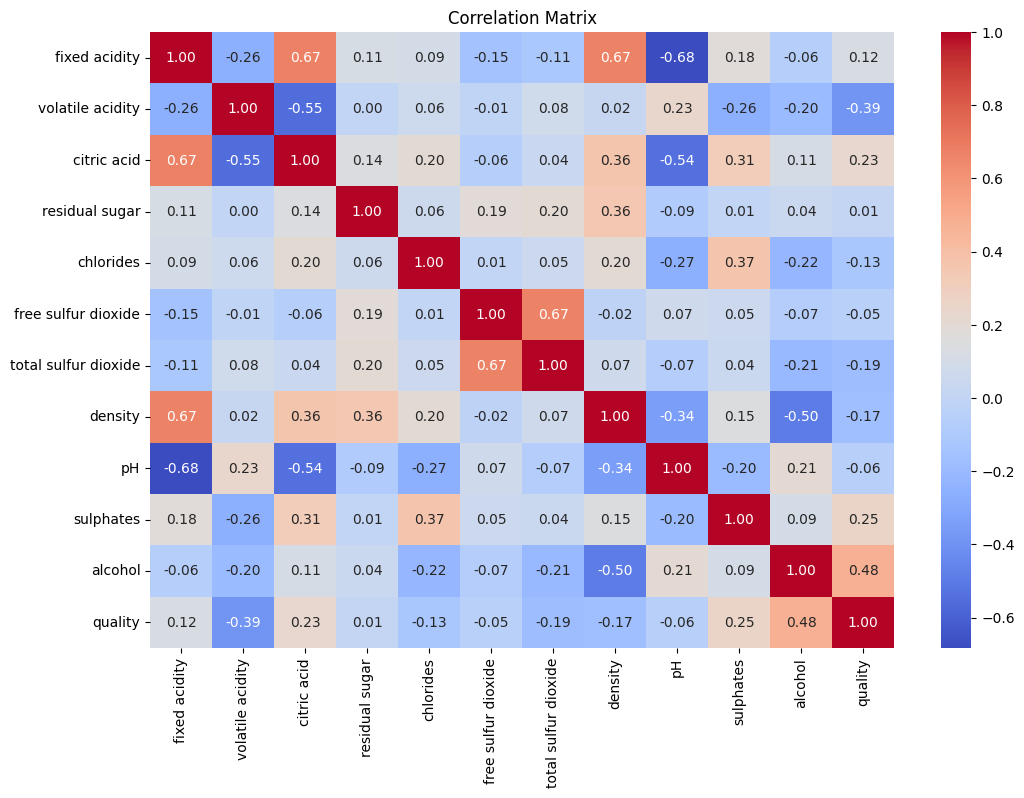

In [5]:
df.describe()
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='quality')

plt.title('Distribution of Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Number of Samples')
plt.show()
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')

plt.title('Correlation Matrix')
plt.show()

In [6]:
X = df.drop('quality', axis=1)
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Training samples: 1279
Testing samples: 320


In [7]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.62      0.73      0.67       136
           6       0.54      0.61      0.57       128
           7       0.71      0.30      0.42        40
           8       0.00      0.00      0.00         3

    accuracy                           0.59       320
   macro avg       0.31      0.27      0.28       320
weighted avg       0.57      0.59      0.57       320



In [8]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.38      0.27      0.32        11
           5       0.69      0.68      0.69       136
           6       0.58      0.55      0.57       128
           7       0.54      0.65      0.59        40
           8       0.14      0.33      0.20         3

    accuracy                           0.61       320
   macro avg       0.39      0.42      0.39       320
weighted avg       0.61      0.61      0.61       320



In [9]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.70      0.76      0.73       136
           6       0.64      0.71      0.67       128
           7       0.77      0.50      0.61        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   macro avg       0.43      0.38      0.40       320
weighted avg       0.65      0.68      0.66       320



In [10]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_xgb = le.fit_transform(y_train)
y_test_xgb = le.transform(y_test)

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(X_train, y_train_xgb)

xgb_pred_encoded = xgb.predict(X_test)

xgb_pred = le.inverse_transform(xgb_pred_encoded)

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.69      0.73      0.71       136
           6       0.63      0.70      0.67       128
           7       0.77      0.60      0.68        40
           8       0.25      0.33      0.29         3

    accuracy                           0.67       320
   macro avg       0.39      0.39      0.39       320
weighted avg       0.65      0.67      0.66       320



In [11]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred, average='weighted'),
        precision_score(y_test, dt_pred, average='weighted'),
        precision_score(y_test, rf_pred, average='weighted'),
        precision_score(y_test, xgb_pred, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, lr_pred, average='weighted'),
        recall_score(y_test, dt_pred, average='weighted'),
        recall_score(y_test, rf_pred, average='weighted'),
        recall_score(y_test, xgb_pred, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test, lr_pred, average='weighted'),
        f1_score(y_test, dt_pred, average='weighted'),
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, xgb_pred, average='weighted')
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.590625,0.569525,0.590625,0.567298
1,Decision Tree,0.606250,0.609688,0.606250,0.606572
2,Random Forest,0.675000,0.654035,0.675000,0.659410
3,XGBoost,0.668750,0.646870,0.668750,0.655465


1. CLASS DISTRIBUTION
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

2. RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.70      0.76      0.73       136
           6       0.64      0.71      0.67       128
           7       0.77      0.50      0.61        40
           8       0.50      0.33      0.40         3

    accuracy                           0.68       320
   macro avg       0.43      0.38      0.40       320
weighted avg       0.65      0.68      0.66       320


3. RANDOM FOREST PARAMETERS
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0,

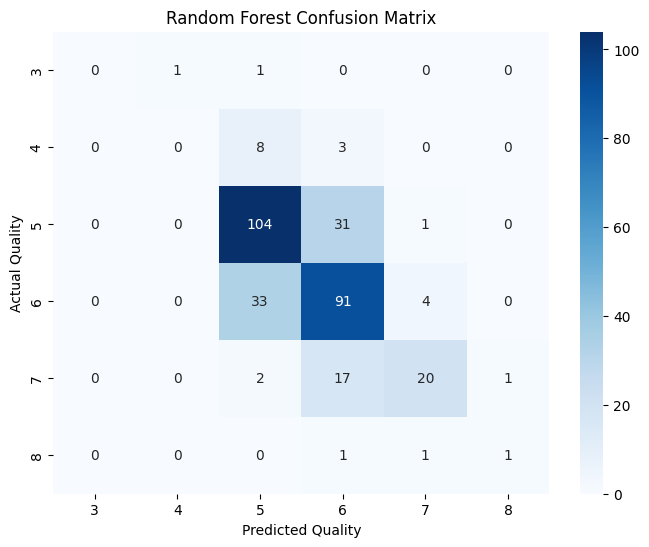

In [12]:
# Check current Random Forest performance and dataset balance

print("=" * 50)
print("1. CLASS DISTRIBUTION")
print("=" * 50)
print(y.value_counts().sort_index())

print("\n" + "=" * 50)
print("2. RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 50)
print(classification_report(y_test, rf_pred))

print("\n" + "=" * 50)
print("3. RANDOM FOREST PARAMETERS")
print("=" * 50)
print(rf.get_params())

print("\n" + "=" * 50)
print("4. CURRENT MODEL ACCURACY")
print("=" * 50)
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("Random Forest F1 Score:", f1_score(y_test, rf_pred, average='weighted'))

print("\n" + "=" * 50)
print("5. CONFUSION MATRIX")
print("=" * 50)

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("Random Forest Confusion Matrix")
plt.show()

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'criterion': 'gini'}

Tuned Random Forest Accuracy:
0.696875

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.72      0.77      0.74       136
           6       0.65      0.73      0.69       128
           7       0.79      0.57      0.67        40
           8       1.00      0.33      0.50         3

    accuracy                           0.70       320
   macro avg       0.53      0.40      0.43       320
weighted avg       0.68      0.70      0.68       320



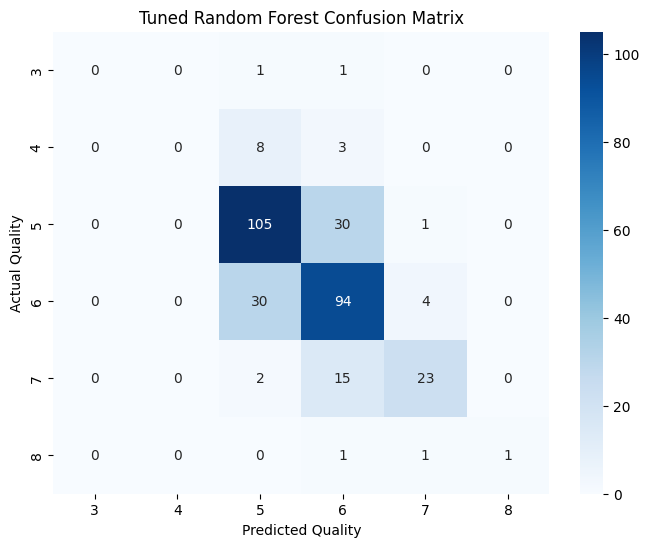

In [13]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [None, 10, 15, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

search = RandomizedSearchCV(
    rf,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_rf = search.best_estimator_
rf_pred_tuned = best_rf.predict(X_test)

print("\nBest Parameters:")
print(search.best_params_)

print("\nTuned Random Forest Accuracy:")
print(accuracy_score(y_test, rf_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred_tuned))

cm = confusion_matrix(y_test, rf_pred_tuned)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

Fitting 3 folds for each of 15 candidates, totalling 45 fits

BEST XGBOOST PARAMETERS
{'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 1.0}

TUNED XGBOOST RESULTS
Accuracy: 0.640625

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.25      0.09      0.13        11
           5       0.72      0.71      0.72       136
           6       0.59      0.66      0.63       128
           7       0.60      0.53      0.56        40
           8       0.33      0.33      0.33         3

    accuracy                           0.64       320
   macro avg       0.42      0.39      0.39       320
weighted avg       0.63      0.64      0.63       320



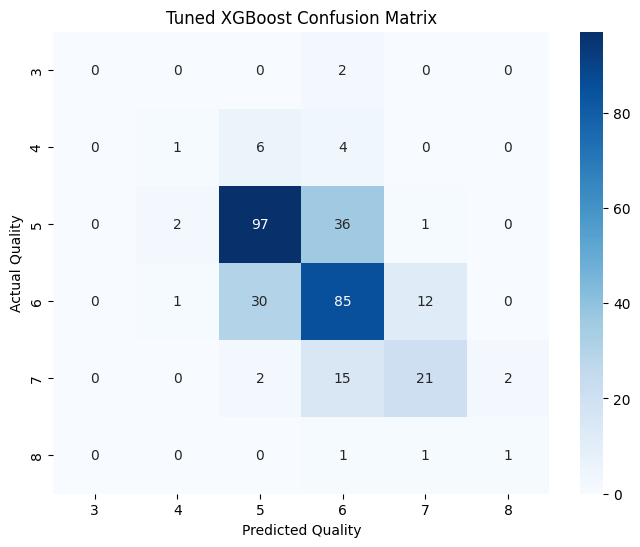

In [14]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

# Encode classes for XGBoost
le = LabelEncoder()

y_train_xgb = le.fit_transform(y_train)
y_test_xgb = le.transform(y_test)

# Base XGBoost
xgb = XGBClassifier(
    objective='multi:softmax',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Parameter combinations
param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.03, 0.05, 0.08, 0.1],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.3]
}

search_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_grid,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search_xgb.fit(X_train, y_train_xgb)

best_xgb = search_xgb.best_estimator_

# Prediction
xgb_pred_encoded = best_xgb.predict(X_test)
xgb_pred_tuned = le.inverse_transform(xgb_pred_encoded)

print("\n" + "=" * 50)
print("BEST XGBOOST PARAMETERS")
print("=" * 50)
print(search_xgb.best_params_)

print("\n" + "=" * 50)
print("TUNED XGBOOST RESULTS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test, xgb_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred_tuned))

# Confusion matrix
cm = confusion_matrix(y_test, xgb_pred_tuned)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.title("Tuned XGBoost Confusion Matrix")
plt.show()

3-Class Distribution:
quality
0      63
1    1319
2     217
Name: count, dtype: int64

RANDOM FOREST - 3 CLASS
Accuracy: 0.8875
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        13
           1       0.90      0.97      0.93       264
           2       0.76      0.67      0.72        43

    accuracy                           0.89       320
   macro avg       0.56      0.55      0.55       320
weighted avg       0.85      0.89      0.87       320



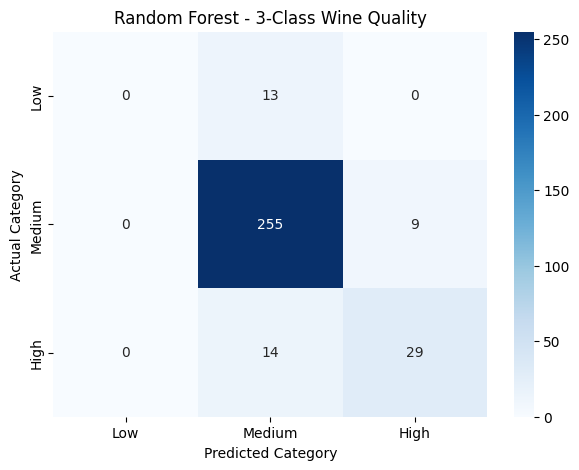


XGBOOST - 3 CLASS
Accuracy: 0.878125
              precision    recall  f1-score   support

           0       0.50      0.15      0.24        13
           1       0.92      0.93      0.93       264
           2       0.67      0.77      0.72        43

    accuracy                           0.88       320
   macro avg       0.70      0.62      0.63       320
weighted avg       0.87      0.88      0.87       320



In [15]:
# 3-Class Wine Quality Prediction
# Low = 3,4
# Medium = 5,6
# High = 7,8

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Create 3 quality categories
def quality_category(q):
    if q <= 4:
        return 0       # Low
    elif q <= 6:
        return 1       # Medium
    else:
        return 2       # High

y_3class = df['quality'].apply(quality_category)

print("3-Class Distribution:")
print(y_3class.value_counts().sort_index())

# Split
X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(
    X,
    y_3class,
    test_size=0.2,
    random_state=42,
    stratify=y_3class
)

# Random Forest
rf_3 = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_3.fit(X_train_3, y_train_3)

rf_3_pred = rf_3.predict(X_test_3)

print("\n" + "=" * 50)
print("RANDOM FOREST - 3 CLASS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_3, rf_3_pred))
print(classification_report(y_test_3, rf_3_pred))

cm = confusion_matrix(y_test_3, rf_3_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Random Forest - 3-Class Wine Quality")
plt.show()

# XGBoost
xgb_3 = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=1.0,
    min_child_weight=3,
    gamma=0.1,
    objective='multi:softmax',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_3.fit(X_train_3, y_train_3)

xgb_3_pred = xgb_3.predict(X_test_3)

print("\n" + "=" * 50)
print("XGBOOST - 3 CLASS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_3, xgb_3_pred))
print(classification_report(y_test_3, xgb_3_pred))

BALANCED RANDOM FOREST - 3 CLASS
Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.90      0.96      0.93       264
        High       0.73      0.63      0.68        43

    accuracy                           0.88       320
   macro avg       0.54      0.53      0.53       320
weighted avg       0.84      0.88      0.86       320



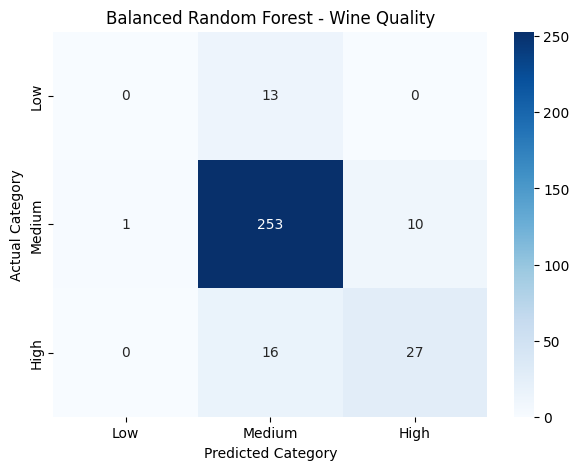

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Balanced Random Forest
rf_balanced = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train_3, y_train_3)

rf_balanced_pred = rf_balanced.predict(X_test_3)

print("=" * 50)
print("BALANCED RANDOM FOREST - 3 CLASS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_3, rf_balanced_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_3,
    rf_balanced_pred,
    target_names=['Low', 'Medium', 'High']
))

cm = confusion_matrix(y_test_3, rf_balanced_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Balanced Random Forest - Wine Quality")
plt.show()

NEW CLASS DISTRIBUTION
quality
0    744
1    638
2    217
Name: count, dtype: int64

RANDOM FOREST - NEW 3 CLASS
Accuracy: 0.746875

Classification Report:
              precision    recall  f1-score   support

         Low       0.80      0.83      0.81       149
      Medium       0.68      0.69      0.68       128
        High       0.76      0.65      0.70        43

    accuracy                           0.75       320
   macro avg       0.75      0.72      0.73       320
weighted avg       0.75      0.75      0.75       320



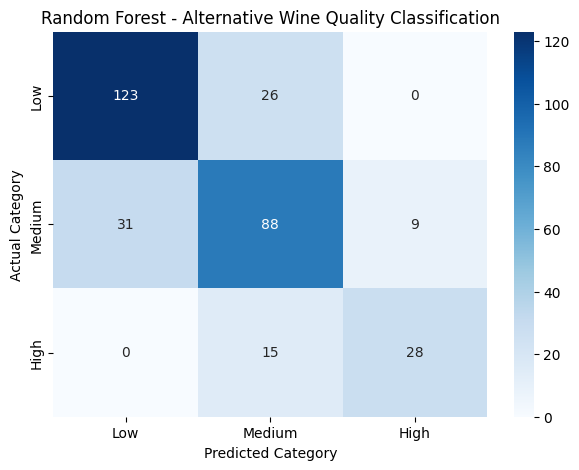

In [17]:
# Alternative 3-Class Wine Quality Classification
# Low    = Quality <= 5
# Medium = Quality 6
# High   = Quality >= 7

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create new categories
def quality_category_new(q):
    if q <= 5:
        return 0       # Low
    elif q == 6:
        return 1       # Medium
    else:
        return 2       # High

y_new = df['quality'].apply(quality_category_new)

print("=" * 50)
print("NEW CLASS DISTRIBUTION")
print("=" * 50)
print(y_new.value_counts().sort_index())

# Split
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X,
    y_new,
    test_size=0.2,
    random_state=42,
    stratify=y_new
)

# Random Forest
rf_new = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_new.fit(X_train_new, y_train_new)

rf_new_pred = rf_new.predict(X_test_new)

print("\n" + "=" * 50)
print("RANDOM FOREST - NEW 3 CLASS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_new, rf_new_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_new,
    rf_new_pred,
    target_names=['Low', 'Medium', 'High']
))

# Confusion Matrix
cm = confusion_matrix(y_test_new, rf_new_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Random Forest - Alternative Wine Quality Classification")

plt.show()

FEATURE-ENGINEERED RANDOM FOREST
Accuracy: 0.8875

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.91      0.96      0.93       264
        High       0.75      0.70      0.72        43

    accuracy                           0.89       320
   macro avg       0.55      0.55      0.55       320
weighted avg       0.85      0.89      0.87       320



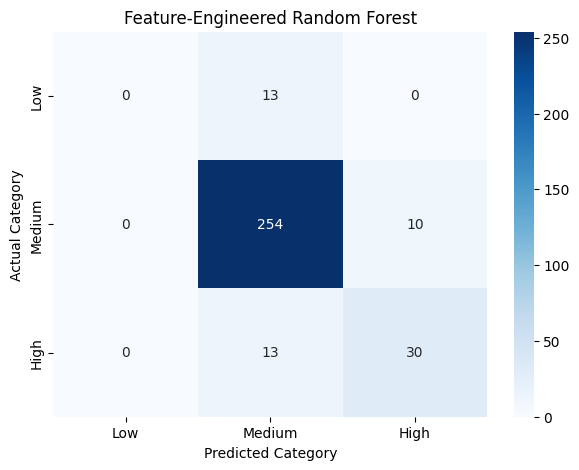

In [18]:
# Feature Engineering + Random Forest
# Original 3-class grouping:
# Low = 3,4
# Medium = 5,6
# High = 7,8

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Copy original features
X_fe = df.drop('quality', axis=1).copy()

# Feature engineering
X_fe['total_acidity'] = X_fe['fixed acidity'] + X_fe['volatile acidity'] + X_fe['citric acid']

X_fe['free_so2_ratio'] = X_fe['free sulfur dioxide'] / (X_fe['total sulfur dioxide'] + 1)

X_fe['sulfur_ratio'] = X_fe['total sulfur dioxide'] / (X_fe['free sulfur dioxide'] + 1)

X_fe['alcohol_density_ratio'] = X_fe['alcohol'] / X_fe['density']

X_fe['sulphate_chloride_ratio'] = X_fe['sulphates'] / (X_fe['chlorides'] + 0.01)

X_fe['acid_ph_interaction'] = X_fe['fixed acidity'] * X_fe['pH']

X_fe['alcohol_sulphates'] = X_fe['alcohol'] * X_fe['sulphates']

X_fe['volatile_citric_ratio'] = X_fe['volatile acidity'] / (X_fe['citric acid'] + 0.01)

# Target: 3-class original grouping
y_fe = df['quality'].apply(
    lambda q: 0 if q <= 4 else (1 if q <= 6 else 2)
)

# Train-test split
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42,
    stratify=y_fe
)

# Random Forest
rf_fe = RandomForestClassifier(
    n_estimators=800,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    criterion='entropy',
    random_state=42,
    n_jobs=-1
)

rf_fe.fit(X_train_fe, y_train_fe)

rf_fe_pred = rf_fe.predict(X_test_fe)

print("=" * 50)
print("FEATURE-ENGINEERED RANDOM FOREST")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_fe, rf_fe_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_fe,
    rf_fe_pred,
    target_names=['Low', 'Medium', 'High']
))

cm = confusion_matrix(y_test_fe, rf_fe_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Feature-Engineered Random Forest")
plt.show()

RANDOM FOREST + XGBOOST ENSEMBLE
Accuracy: 0.8875

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.91      0.96      0.93       264
        High       0.76      0.72      0.74        43

    accuracy                           0.89       320
   macro avg       0.56      0.56      0.56       320
weighted avg       0.85      0.89      0.87       320



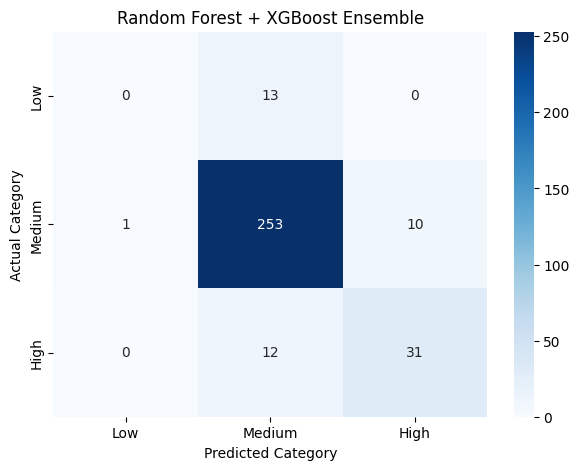

In [19]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Random Forest
rf_vote = RandomForestClassifier(
    n_estimators=800,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# XGBoost
xgb_vote = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=1.0,
    min_child_weight=3,
    gamma=0.1,
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

# Voting ensemble
ensemble = VotingClassifier(
    estimators=[
        ('rf', rf_vote),
        ('xgb', xgb_vote)
    ],
    voting='soft',
    weights=[2, 1]
)

ensemble.fit(X_train_3, y_train_3)

ensemble_pred = ensemble.predict(X_test_3)

print("=" * 50)
print("RANDOM FOREST + XGBOOST ENSEMBLE")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_3, ensemble_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_3,
    ensemble_pred,
    target_names=['Low', 'Medium', 'High']
))

cm = confusion_matrix(y_test_3, ensemble_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Random Forest + XGBoost Ensemble")
plt.show()

In [20]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("=" * 50)
print("BEFORE OVERSAMPLING")
print("=" * 50)
print(y_train_3.value_counts().sort_index())

ros = RandomOverSampler(
    sampling_strategy={
        0: 300,
        1: 1055,
        2: 350
    },
    random_state=42
)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_3,
    y_train_3
)

print("\n" + "=" * 50)
print("AFTER OVERSAMPLING")
print("=" * 50)
print(y_train_ros.value_counts().sort_index())

rf_ros = RandomForestClassifier(
    n_estimators=1000,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    criterion='entropy',
    random_state=42,
    n_jobs=-1
)

rf_ros.fit(X_train_ros, y_train_ros)

ros_pred = rf_ros.predict(X_test_3)

print("\n" + "=" * 50)
print("RANDOM OVERSAMPLING + RANDOM FOREST")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_3, ros_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_3,
    ros_pred,
    target_names=['Low', 'Medium', 'High']
))

BEFORE OVERSAMPLING
quality
0      50
1    1055
2     174
Name: count, dtype: int64

AFTER OVERSAMPLING
quality
0     300
1    1055
2     350
Name: count, dtype: int64

RANDOM OVERSAMPLING + RANDOM FOREST
Accuracy: 0.88125

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.92      0.94      0.93       264
        High       0.72      0.77      0.74        43

    accuracy                           0.88       320
   macro avg       0.54      0.57      0.56       320
weighted avg       0.85      0.88      0.87       320



In [21]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report

extra = ExtraTreesClassifier(
    n_estimators=1500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    criterion='entropy',
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

extra.fit(X_train_3, y_train_3)

extra_pred = extra.predict(X_test_3)

print("=" * 50)
print("EXTRA TREES RESULTS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_test_3, extra_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_3,
    extra_pred,
    target_names=['Low', 'Medium', 'High']
))

EXTRA TREES RESULTS
Accuracy: 0.8875

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.90      0.97      0.93       264
        High       0.82      0.63      0.71        43

    accuracy                           0.89       320
   macro avg       0.57      0.53      0.55       320
weighted avg       0.85      0.89      0.87       320



In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# ==========================================
# STAGE 1: LOW vs NON-LOW
# ==========================================

y_train_stage1 = (y_train_3 == 0).astype(int)
y_test_stage1 = (y_test_3 == 0).astype(int)

rf_stage1 = RandomForestClassifier(
    n_estimators=1200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    criterion='entropy',
    random_state=42,
    n_jobs=-1
)

rf_stage1.fit(X_train_3, y_train_stage1)

stage1_pred = rf_stage1.predict(X_test_3)


# ==========================================
# STAGE 2: MEDIUM vs HIGH
# ==========================================

train_non_low = y_train_3 != 0

X_train_stage2 = X_train_3[train_non_low]
y_train_stage2 = y_train_3[train_non_low]

rf_stage2 = RandomForestClassifier(
    n_estimators=1200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    criterion='entropy',
    random_state=42,
    n_jobs=-1
)

rf_stage2.fit(X_train_stage2, y_train_stage2)

stage2_pred = rf_stage2.predict(X_test_3)


# ==========================================
# COMBINE PREDICTIONS
# ==========================================

hierarchical_pred = np.zeros(len(X_test_3), dtype=int)

for i in range(len(X_test_3)):

    if stage1_pred[i] == 1:
        hierarchical_pred[i] = 0
    else:
        hierarchical_pred[i] = stage2_pred[i]


# ==========================================
# RESULTS
# ==========================================

print("=" * 50)
print("HIERARCHICAL RANDOM FOREST RESULTS")
print("=" * 50)

print("Accuracy:", accuracy_score(
    y_test_3,
    hierarchical_pred
))

print("\nClassification Report:")

print(classification_report(
    y_test_3,
    hierarchical_pred,
    target_names=['Low', 'Medium', 'High']
))

HIERARCHICAL RANDOM FOREST RESULTS
Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.90      0.96      0.93       264
        High       0.73      0.63      0.68        43

    accuracy                           0.88       320
   macro avg       0.54      0.53      0.53       320
weighted avg       0.84      0.88      0.86       320



In [23]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_3 = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_dist = {
    'n_estimators': [300, 500, 800],
    'max_depth': [None, 15, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'criterion': ['gini', 'entropy']
}

search = RandomizedSearchCV(
    rf_3,
    param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train_3, y_train_3)

best_rf = search.best_estimator_
pred = best_rf.predict(X_test_3)

print("\n" + "=" * 50)
print("TUNED RANDOM FOREST")
print("=" * 50)

print("Best Parameters:")
print(search.best_params_)

print("\nCV Accuracy:", search.best_score_)
print("Test Accuracy:", accuracy_score(y_test_3, pred))

print("\nClassification Report:")
print(classification_report(
    y_test_3,
    pred,
    target_names=['Low', 'Medium', 'High']
))

Fitting 3 folds for each of 10 candidates, totalling 30 fits

TUNED RANDOM FOREST
Best Parameters:
{'n_estimators': 800, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15, 'criterion': 'entropy'}

CV Accuracy: 0.8600400215500654
Test Accuracy: 0.88125

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.90      0.96      0.93       264
        High       0.74      0.65      0.69        43

    accuracy                           0.88       320
   macro avg       0.55      0.54      0.54       320
weighted avg       0.84      0.88      0.86       320



Final Model Accuracy: 0.8875

Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.90      0.97      0.93       264
        High       0.76      0.67      0.72        43

    accuracy                           0.89       320
   macro avg       0.56      0.55      0.55       320
weighted avg       0.85      0.89      0.87       320



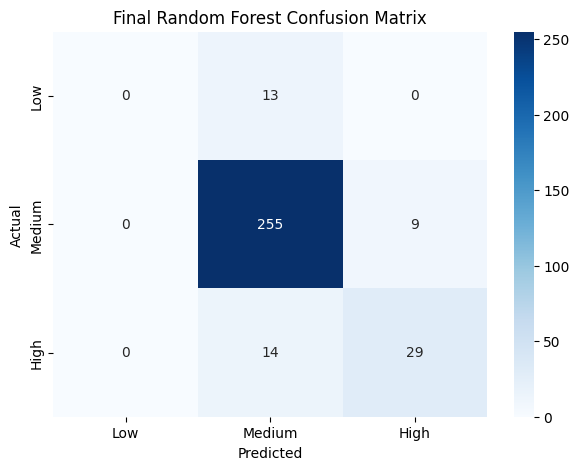

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

final_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    criterion='gini',
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_3, y_train_3)

final_pred = final_rf.predict(X_test_3)

print("Final Model Accuracy:", accuracy_score(y_test_3, final_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_3,
    final_pred,
    target_names=['Low', 'Medium', 'High']
))

cm = confusion_matrix(y_test_3, final_pred)

plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Random Forest Confusion Matrix")
plt.show()

                 Feature  Importance
10               alcohol    0.147493
1       volatile acidity    0.120604
9              sulphates    0.105910
7                density    0.088129
6   total sulfur dioxide    0.085444
2            citric acid    0.082529
4              chlorides    0.079763
0          fixed acidity    0.078502
3         residual sugar    0.076605
8                     pH    0.070894
5    free sulfur dioxide    0.064127


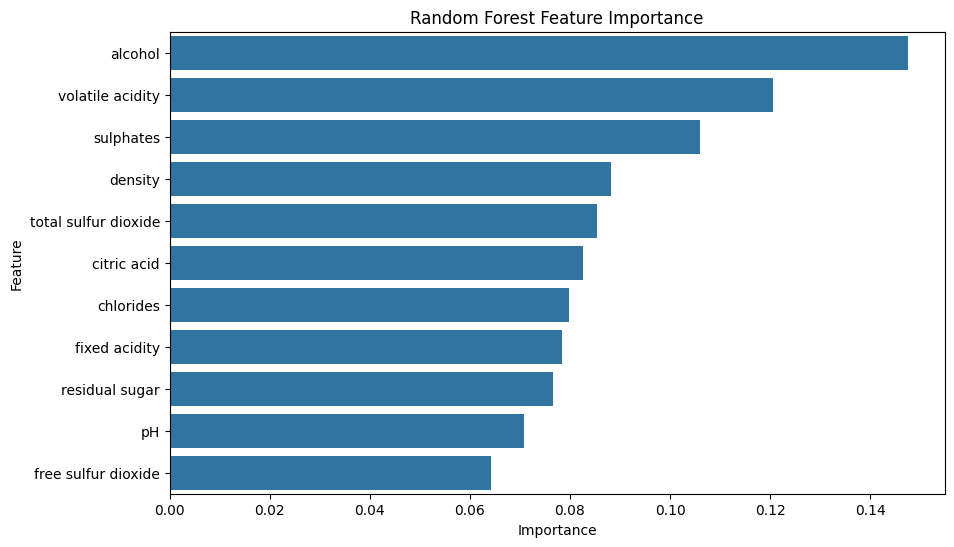

In [25]:
importance = pd.DataFrame({
    'Feature': X_train_3.columns,
    'Importance': final_rf.feature_importances_
})

importance = importance.sort_values(
    'Importance',
    ascending=False
)

print(importance)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()


In [26]:
!pip install shap -q

import shap
import matplotlib.pyplot as plt

# Use a manageable sample for SHAP
X_shap = X_test_3.copy()

# Create SHAP explainer
explainer = shap.TreeExplainer(final_rf)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed.")
print("Number of classes:", len(shap_values))
print("Number of features:", X_shap.shape[1])

SHAP calculation completed.
Number of classes: 320
Number of features: 11


SHAP values shape: (320, 11, 3)

SHAP Summary: Low


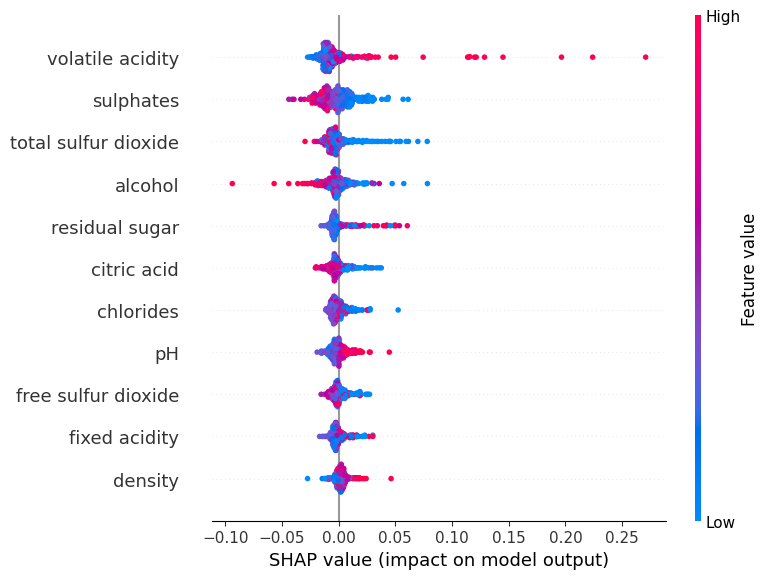


SHAP Summary: Medium


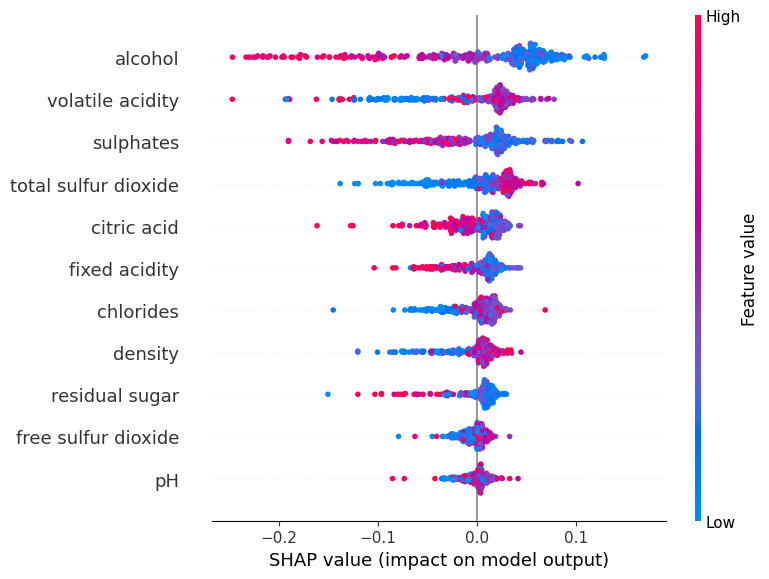


SHAP Summary: High


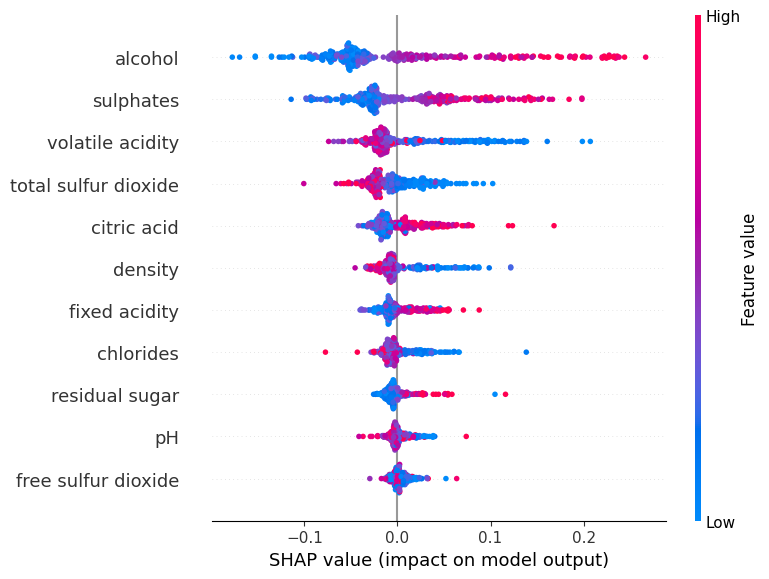

In [27]:
print("SHAP values shape:", np.array(shap_values).shape)

class_names = ['Low', 'Medium', 'High']

for i in range(3):

    print("\nSHAP Summary:", class_names[i])

    shap.summary_plot(
        shap_values[:, :, i],
        X_shap,
        show=True
    )

GLOBAL SHAP FEATURE IMPORTANCE
                 Feature  SHAP Importance
10               alcohol         0.048813
9              sulphates         0.033140
1       volatile acidity         0.029617
6   total sulfur dioxide         0.020148
2            citric acid         0.015636
0          fixed acidity         0.012803
7                density         0.012727
4              chlorides         0.011889
3         residual sugar         0.010529
8                     pH         0.006829
5    free sulfur dioxide         0.006585


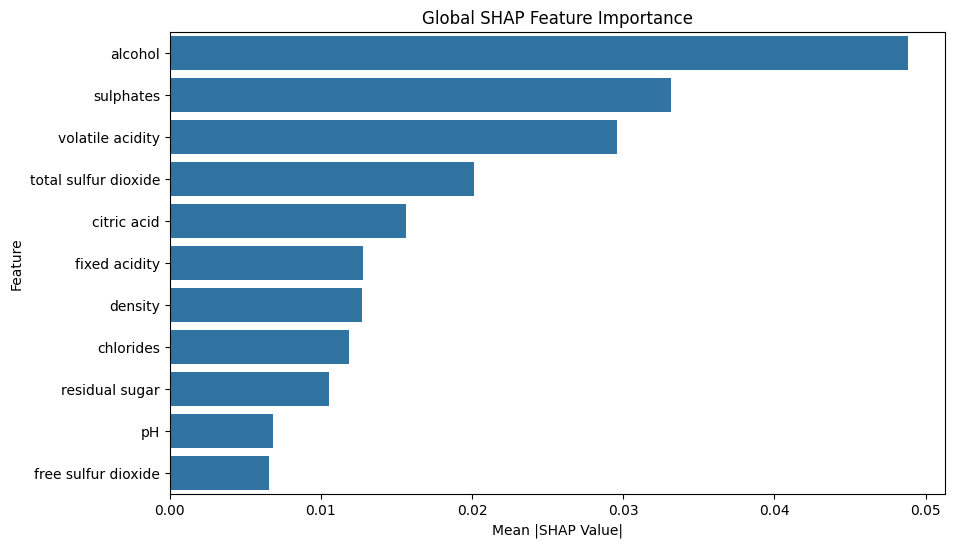

In [28]:
# Global SHAP Feature Importance

shap_array = np.array(shap_values)

# Mean absolute SHAP value across samples and classes
global_shap_importance = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

shap_importance_df = pd.DataFrame({
    'Feature': X_shap.columns,
    'SHAP Importance': global_shap_importance
})

shap_importance_df = shap_importance_df.sort_values(
    'SHAP Importance',
    ascending=False
)

print("=" * 50)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 50)

print(shap_importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=shap_importance_df,
    x='SHAP Importance',
    y='Feature'
)

plt.title("Global SHAP Feature Importance")
plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.show()


SHAP IMPORTANCE FOR: Low
                 Feature  SHAP Importance
1       volatile acidity         0.014901
9              sulphates         0.011431
6   total sulfur dioxide         0.008329
10               alcohol         0.008269
3         residual sugar         0.006682
2            citric acid         0.005786
4              chlorides         0.005346
8                     pH         0.004753
5    free sulfur dioxide         0.004438
0          fixed acidity         0.004351
7                density         0.003881


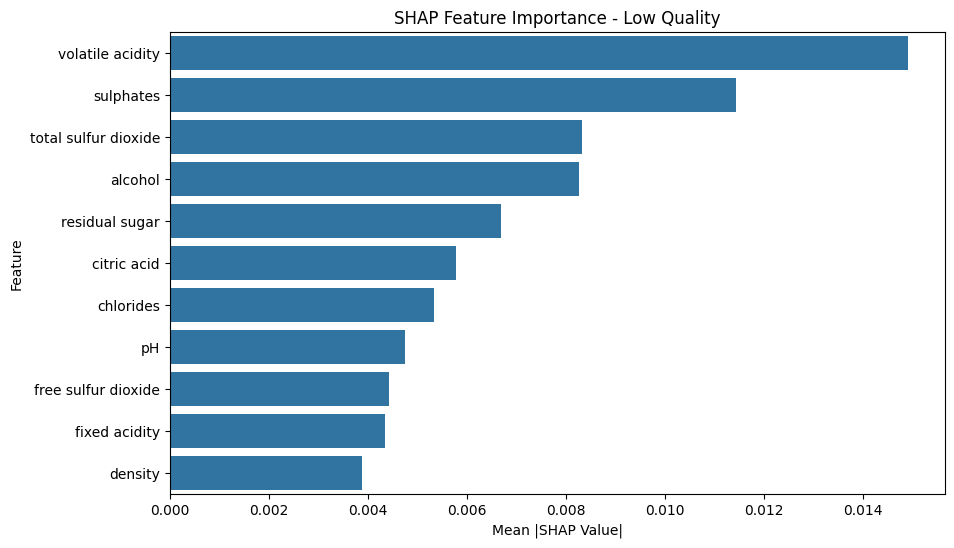


SHAP IMPORTANCE FOR: Medium
                 Feature  SHAP Importance
10               alcohol         0.066958
1       volatile acidity         0.039398
9              sulphates         0.039176
6   total sulfur dioxide         0.029431
2            citric acid         0.020156
0          fixed acidity         0.018453
4              chlorides         0.017130
7                density         0.016533
3         residual sugar         0.015169
5    free sulfur dioxide         0.008656
8                     pH         0.008437


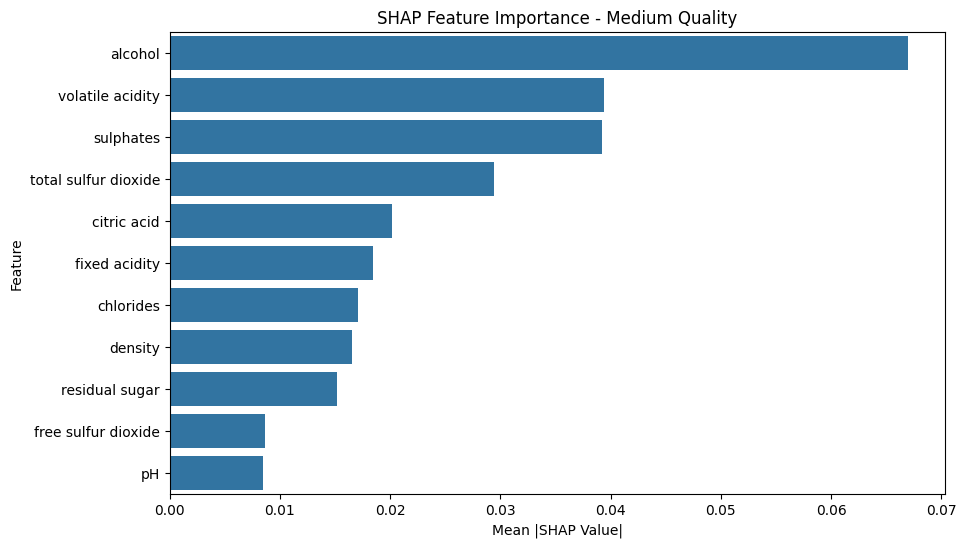


SHAP IMPORTANCE FOR: High
                 Feature  SHAP Importance
10               alcohol         0.071214
9              sulphates         0.048813
1       volatile acidity         0.034551
6   total sulfur dioxide         0.022684
2            citric acid         0.020968
7                density         0.017768
0          fixed acidity         0.015604
4              chlorides         0.013189
3         residual sugar         0.009736
8                     pH         0.007298
5    free sulfur dioxide         0.006660


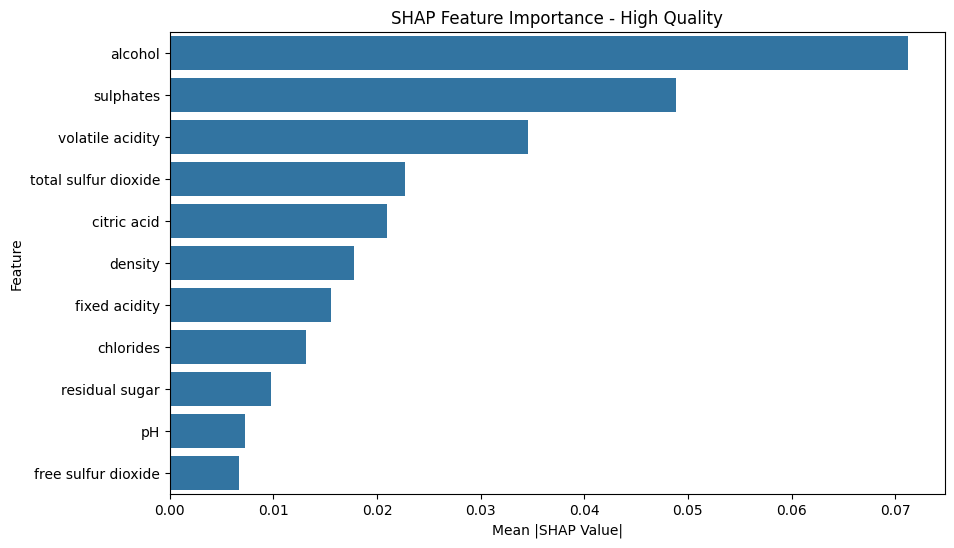

In [29]:
class_names = ['Low', 'Medium', 'High']

for i in range(3):

    class_importance = np.mean(
        np.abs(shap_array[:, :, i]),
        axis=0
    )

    class_df = pd.DataFrame({
        'Feature': X_shap.columns,
        'SHAP Importance': class_importance
    })

    class_df = class_df.sort_values(
        'SHAP Importance',
        ascending=False
    )

    print("\n" + "=" * 55)
    print("SHAP IMPORTANCE FOR:", class_names[i])
    print("=" * 55)

    print(class_df)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=class_df,
        x='SHAP Importance',
        y='Feature'
    )

    plt.title(
        "SHAP Feature Importance - " + class_names[i] + " Quality"
    )

    plt.xlabel("Mean |SHAP Value|")
    plt.ylabel("Feature")

    plt.show()

Sample Index: 0
Actual Class: High
Predicted Class: High

Expected Value: [0.0396638  0.82496325 0.13537295]

Feature Contributions:
                 Feature  Feature Value  SHAP Value
10               alcohol       12.60000    0.231999
9              sulphates        0.75000    0.151420
7                density        0.99486    0.098591
1       volatile acidity        0.38000    0.054844
2            citric acid        0.40000    0.054655
6   total sulfur dioxide       28.00000    0.026722
0          fixed acidity        8.90000    0.023994
5    free sulfur dioxide       12.00000    0.023496
4              chlorides        0.06800    0.018683
3         residual sugar        2.20000   -0.017250
8                     pH        3.27000    0.007474


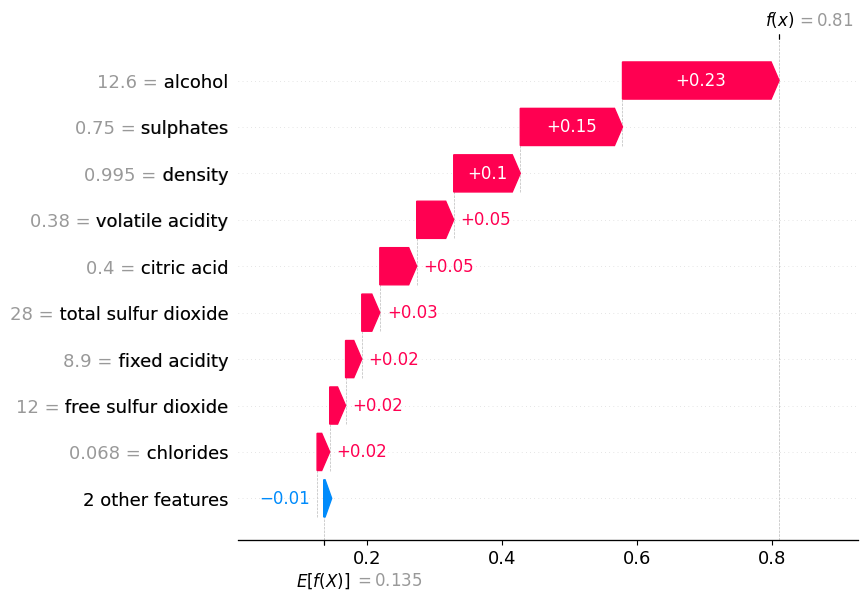

In [30]:
# Select one test sample
idx = 0

class_names = ['Low', 'Medium', 'High']

actual_class = int(y_test_3.iloc[idx])
predicted_class = int(final_pred[idx])

print("Sample Index:", idx)
print("Actual Class:", class_names[actual_class])
print("Predicted Class:", class_names[predicted_class])

# Check expected value format
print("\nExpected Value:", explainer.expected_value)

# Local SHAP values for the predicted class
local_shap = shap_array[idx, :, predicted_class]

print("\nFeature Contributions:")
local_df = pd.DataFrame({
    'Feature': X_shap.columns,
    'SHAP Value': local_shap,
    'Feature Value': X_shap.iloc[idx].values
})

local_df['Absolute SHAP'] = abs(local_df['SHAP Value'])

local_df = local_df.sort_values(
    'Absolute SHAP',
    ascending=False
)

print(local_df[['Feature', 'Feature Value', 'SHAP Value']])

# Local explanation plot
shap.waterfall_plot(
    shap.Explanation(
        values=local_shap,
        base_values=explainer.expected_value[predicted_class],
        data=X_shap.iloc[idx].values,
        feature_names=X_shap.columns
    )
)